# 🧩 Semana 10 · Redes Neuronales Convolucionales (CNN)
## **BaldosaScan: inspector visual de grietas**

**Curso:** Inteligencia Artificial · UNMSM — FISI  
**Objetivo:** enseñar cómo una CNN identifica **patrones locales** para distinguir entre una superficie **intacta**, una **grieta vertical** y una **grieta horizontal**.

> **¿Qué tiene de original?** No usamos MNIST ni imágenes descargadas: creamos un pequeño laboratorio de inspección visual con baldosas simuladas y probamos la red como si fuera un inspector automático.

**Qué vas a ver:**
1. Imágenes de entrenamiento generadas dentro del notebook.
2. Una **CNN (convolución → pooling → clasificación)** comparada con una red densa.
3. Gráficas de aprendizaje, precisión y matriz de confusión.
4. Los **mapas de características** que producen los filtros.
5. Una demostración donde eliges un tipo de baldosa y el modelo la clasifica.

**Ejecución:** en Google Colab selecciona **Entorno de ejecución → Ejecutar todas** (CPU es suficiente). También funciona en un Jupyter local con `torch`, `numpy`, `matplotlib` y `Pillow`.

⚠️ **Importante:** las imágenes son **sintéticas**. Este ejercicio demuestra el principio de una CNN, **no** valida un detector de daños reales.

### 1. Preparar las bibliotecas
- `NumPy`: crear matrices de píxeles.
- `Pillow`: dibujar pequeños defectos.
- `PyTorch`: entrenar una red que **aprende** sus filtros.
- `Matplotlib`: ver imágenes, resultados y filtros.

Una imagen en grises de **32 × 32** es una matriz de **1024 números** entre 0 y 1.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

SEMILLA = 7
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
torch.set_num_threads(2)  # práctico para CPU

NOMBRES = ["Sin grieta", "Grieta vertical", "Grieta horizontal"]
print("✓ Preparación completa. PyTorch:", torch.__version__)

✓ Preparación completa. PyTorch: 2.10.0+cpu


### 2. Construir un dataset propio

Cada baldosa simulada tiene **textura, iluminación ligeramente diferente y pequeñas marcas**. En algunas aparece una línea quebrada vertical u horizontal. Los tres conjuntos se generan **por separado** para evitar reutilizar las mismas imágenes en entrenamiento y prueba.

- **Entrenamiento:** la red ajusta sus filtros.
- **Validación:** observamos si aprende durante las épocas.
- **Prueba:** comprobamos su capacidad con imágenes nuevas que no vio al entrenar.

**Pregunta para la exposición:** ¿puede un mismo filtro aprender a reconocer una grieta aunque cambie de lugar? Esa es una de las ventajas de la **compartición de pesos**.

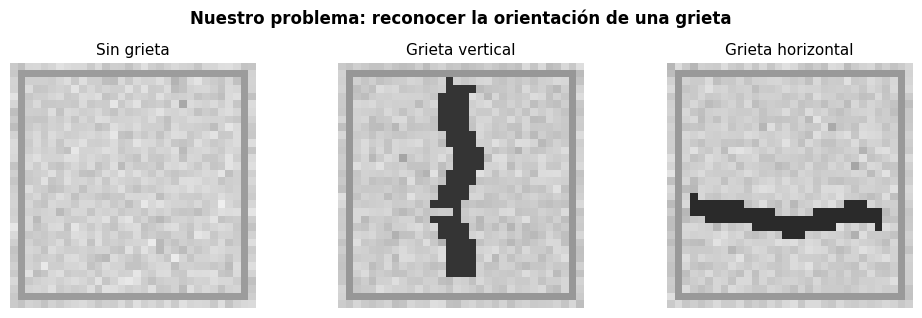

Datos independientes: 780 entrenamiento | 210 validación | 270 prueba


In [2]:
def crear_baldosa(clase, rng):
    """Devuelve una imagen sintética 32×32 (grises, valores 0-1)."""
    fondo = rng.normal(205, 9, size=(32, 32)) + rng.uniform(-10, 10)
    imagen = Image.fromarray(np.uint8(np.clip(fondo, 0, 255)), mode="L")
    lapiz = ImageDraw.Draw(imagen)
    lapiz.rectangle((1, 1, 30, 30), outline=int(rng.integers(145, 185)))

    # Pequeñas imperfecciones presentes en todas las clases.
    for _ in range(int(rng.integers(2, 7))):
        x, y = int(rng.integers(4, 28)), int(rng.integers(4, 28))
        lapiz.point((x, y), fill=int(rng.integers(155, 200)))

    if clase in (1, 2):
        posicion = int(rng.integers(9, 24))
        puntos = []
        for avance in range(3, 29, 2):
            posicion = int(np.clip(posicion + rng.integers(-1, 2), 6, 26))
            puntos.append((posicion, avance) if clase == 1 else (avance, posicion))
        lapiz.line(puntos, fill=int(rng.integers(20, 65)),
                   width=int(rng.integers(3, 5)))

    return np.asarray(imagen, dtype=np.float32) / 255.0


def crear_dataset(por_clase, semilla):
    rng = np.random.default_rng(semilla)
    imagenes, etiquetas = [], []
    for clase in range(3):
        for _ in range(por_clase):
            imagenes.append(crear_baldosa(clase, rng))
            etiquetas.append(clase)
    indices = rng.permutation(len(etiquetas))
    x = torch.tensor(np.array(imagenes)[indices, None, :, :])
    y = torch.tensor(np.array(etiquetas)[indices], dtype=torch.long)
    return x, y

X_ent, y_ent = crear_dataset(260, semilla=10)  # 780 imágenes
X_val, y_val = crear_dataset(70, semilla=20)   # 210 imágenes
X_pru, y_pru = crear_dataset(90, semilla=30)   # 270 imágenes

fig, ejes = plt.subplots(1, 3, figsize=(10, 3.2))
rng_ejemplos = np.random.default_rng(101)
for clase, eje in enumerate(ejes):
    eje.imshow(crear_baldosa(clase, rng_ejemplos), cmap="gray", vmin=0, vmax=1)
    eje.set_title(NOMBRES[clase], fontsize=11)
    eje.axis("off")
plt.suptitle("Nuestro problema: reconocer la orientación de una grieta", fontweight="bold")
plt.tight_layout()
plt.show()
print(f"Datos independientes: {len(X_ent)} entrenamiento | {len(X_val)} validación | {len(X_pru)} prueba")

### 3. Definir dos modelos y comparar sus parámetros

La **CNN** busca patrones pequeños mediante filtros **3 × 3**, reduce el tamaño mediante *max pooling* y resume las respuestas mediante **Global Average Pooling (GAP)**. Después, una capa densa decide la clase.

La **red densa** recibe todos los píxeles a la vez, sin un filtro local compartido. La incluimos como referencia didáctica; **no** es un experimento de comparación controlada entre arquitecturas equivalentes.

| Etapa de la CNN | ¿Qué hace? | En la presentación |
|---|---|---|
| `Conv2d` + `ReLU` | Aprende filtros locales y activa las respuestas útiles | Convolución, kernel y ReLU |
| `MaxPool2d` | Conserva respuestas máximas y reduce resolución | Pooling |
| `AdaptiveAvgPool2d` | Resume cada mapa en un valor | GAP |
| `Linear` | Decide entre las tres clases | Dense / clasificación |

In [3]:
# CNN 2D pequeña: 32×32 → 16×16 → 8×8 → 3 clases.
cnn = nn.Sequential(
    nn.Conv2d(1, 12, kernel_size=3, padding=1), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(12, 24, kernel_size=3, padding=1), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.AdaptiveAvgPool2d((1, 1)),  # Global Average Pooling
    nn.Flatten(),
    nn.Linear(24, 3)
)

# Modelo de referencia: no utiliza convolución.
densa = nn.Sequential(
    nn.Flatten(),
    nn.Linear(32 * 32, 32), nn.ReLU(),
    nn.Linear(32, 3)
)

def parametros(modelo):
    return sum(p.numel() for p in modelo.parameters() if p.requires_grad)

print("CNN:       ", f"{parametros(cnn):,}", "parámetros entrenables")
print("Red densa: ", f"{parametros(densa):,}", "parámetros entrenables")
print("Entrada:   ", tuple(X_ent.shape[1:]), "= 1 canal × 32 × 32")

CNN:        2,811 parámetros entrenables
Red densa:  32,899 parámetros entrenables
Entrada:    (1, 32, 32) = 1 canal × 32 × 32


### 4. Entrenar las redes

En cada **época**, el modelo observa lotes de ejemplos, calcula su error con **entropía cruzada**, y el optimizador **Adam** modifica los pesos mediante retropropagación. Guardamos la precisión y la pérdida de entrenamiento y validación para observar el proceso.

> **Precisión (*accuracy*)**: porcentaje de imágenes clasificadas correctamente. Que la pérdida disminuya y la precisión aumente es una señal de aprendizaje, no una garantía de generalización.

In [4]:
def evaluar(modelo, x, y):
    modelo.eval()
    with torch.no_grad():
        salida = modelo(x)
        perdida = nn.functional.cross_entropy(salida, y).item()
        aciertos = (salida.argmax(dim=1) == y).float().mean().item()
    return perdida, aciertos


def entrenar(modelo, epocas=12):
    lotes = DataLoader(TensorDataset(X_ent, y_ent),
                       batch_size=32, shuffle=True)
    optimizador = torch.optim.Adam(modelo.parameters(), lr=0.001)
    historia = {"perdida_ent": [], "perdida_val": [],
                "acc_ent": [], "acc_val": []}

    for epoca in range(epocas):
        modelo.train()
        for imagenes, etiquetas in lotes:
            optimizador.zero_grad()
            perdida = nn.functional.cross_entropy(modelo(imagenes), etiquetas)
            perdida.backward()       # Propagación del error
            optimizador.step()       # Actualización de filtros y pesos

        pe, ae = evaluar(modelo, X_ent, y_ent)
        pv, av = evaluar(modelo, X_val, y_val)
        for clave, valor in zip(historia, (pe, pv, ae, av)):
            historia[clave].append(valor)
        print(f"Época {epoca+1:02d}/{epocas} | entrenamiento {ae:.1%} | validación {av:.1%}")

    return historia

print("========== ENTRENAMIENTO CNN ==========")
h_cnn = entrenar(cnn)
print("\n========== ENTRENAMIENTO RED DENSA ==========")
h_densa = entrenar(densa)

========== ENTRENAMIENTO CNN ==========


Época 01/12 | entrenamiento 50.9% | validación 55.2%


Época 02/12 | entrenamiento 57.9% | validación 61.4%
Época 03/12 | entrenamiento 66.7% | validación 66.7%


Época 04/12 | entrenamiento 40.3% | validación 39.5%
Época 05/12 | entrenamiento 66.7% | validación 66.7%


Época 06/12 | entrenamiento 69.9% | validación 69.5%
Época 07/12 | entrenamiento 66.7% | validación 66.7%


Época 08/12 | entrenamiento 97.9% | validación 98.1%
Época 09/12 | entrenamiento 99.0% | validación 99.0%


Época 10/12 | entrenamiento 68.3% | validación 68.6%
Época 11/12 | entrenamiento 99.4% | validación 99.5%


Época 12/12 | entrenamiento 99.2% | validación 99.5%

========== ENTRENAMIENTO RED DENSA ==========
Época 01/12 | entrenamiento 33.3% | validación 33.3%
Época 02/12 | entrenamiento 31.8% | validación 31.9%
Época 03/12 | entrenamiento 66.4% | validación 67.1%
Época 04/12 | entrenamiento 39.0% | validación 37.6%
Época 05/12 | entrenamiento 58.7% | validación 53.8%
Época 06/12 | entrenamiento 72.2% | validación 71.0%
Época 07/12 | entrenamiento 75.6% | validación 71.9%
Época 08/12 | entrenamiento 84.6% | validación 81.4%
Época 09/12 | entrenamiento 92.2% | validación 89.0%
Época 10/12 | entrenamiento 92.4% | validación 89.0%


Época 11/12 | entrenamiento 92.6% | validación 89.0%
Época 12/12 | entrenamiento 88.8% | validación 86.7%


### 5. Resultados sobre imágenes nunca utilizadas para entrenar

La **curva de precisión** muestra cuánto aprende cada modelo. La **matriz de confusión** permite ver exactamente qué clases acierta o confunde la CNN. El resultado puede cambiar ligeramente al variar la semilla o el entrenamiento.

**Importante:** no hay que concluir que *toda* CNN supera a *toda* red densa; la comparación ilustra qué sucede **en este problema sintético** con estas dos arquitecturas concretas.

CNN       → precisión en PRUEBA: 99.6% | 2,811 parámetros
Red densa → precisión en PRUEBA: 83.0% | 32,899 parámetros


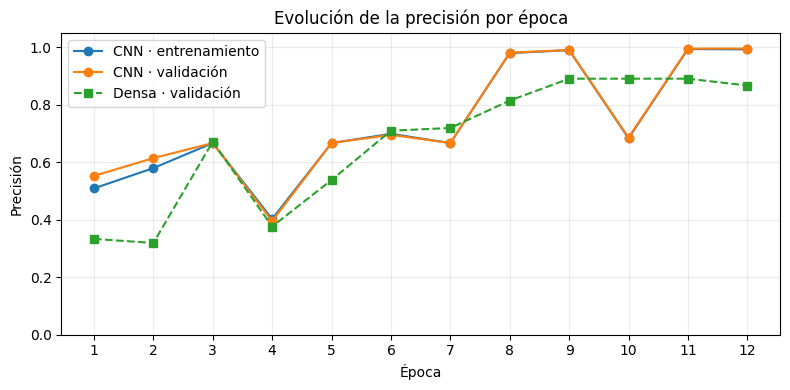

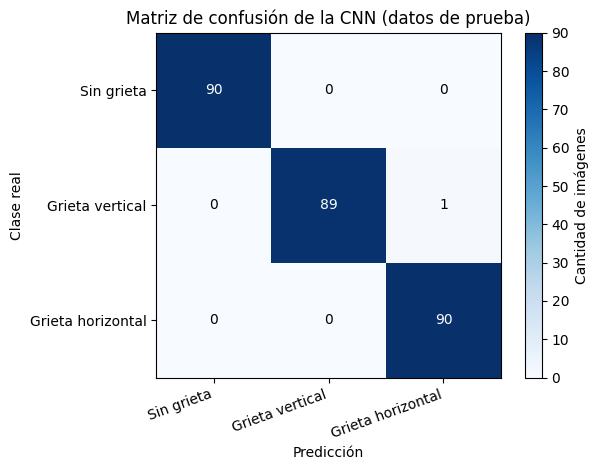

In [5]:
_, acc_cnn = evaluar(cnn, X_pru, y_pru)
_, acc_densa = evaluar(densa, X_pru, y_pru)

print(f"CNN       → precisión en PRUEBA: {acc_cnn:.1%} | {parametros(cnn):,} parámetros")
print(f"Red densa → precisión en PRUEBA: {acc_densa:.1%} | {parametros(densa):,} parámetros")

plt.figure(figsize=(8, 4))
plt.plot(h_cnn["acc_ent"], marker="o", label="CNN · entrenamiento")
plt.plot(h_cnn["acc_val"], marker="o", label="CNN · validación")
plt.plot(h_densa["acc_val"], marker="s", linestyle="--", label="Densa · validación")
plt.title("Evolución de la precisión por época")
plt.xlabel("Época")
plt.ylabel("Precisión")
plt.ylim(0, 1.05)
plt.xticks(range(len(h_cnn["acc_ent"])), range(1, len(h_cnn["acc_ent"]) + 1))
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

# Matriz de confusión calculada sin dependencias adicionales.
cnn.eval()
with torch.no_grad():
    predicciones = cnn(X_pru).argmax(dim=1).numpy()
matriz = np.zeros((3, 3), dtype=int)
for real, pred in zip(y_pru.numpy(), predicciones):
    matriz[real, pred] += 1

plt.figure(figsize=(6.3, 4.8))
plt.imshow(matriz, cmap="Blues")
plt.title("Matriz de confusión de la CNN (datos de prueba)")
plt.xticks(range(3), NOMBRES, rotation=20, ha="right")
plt.yticks(range(3), NOMBRES)
plt.xlabel("Predicción")
plt.ylabel("Clase real")
for fila in range(3):
    for col in range(3):
        plt.text(col, fila, matriz[fila, col], ha="center", va="center",
                 color="white" if matriz[fila, col] > matriz.max() / 2 else "black")
plt.colorbar(label="Cantidad de imágenes")
plt.tight_layout()
plt.show()

### 6. ¿Qué «ve» la CNN? Mapas de características

La primera capa aplica **12 filtros aprendidos** sobre la imagen. Cada uno responde de forma distinta. Mostramos dos de los mapas con mayor variación y el efecto del **max pooling** en uno de ellos.

**Para explicar:** un filtro se reutiliza en muchas posiciones; por eso puede responder a una marca vertical aunque aparezca en otra parte de la baldosa. Los mapas son **activaciones internas**, no una explicación causal completa de la decisión.

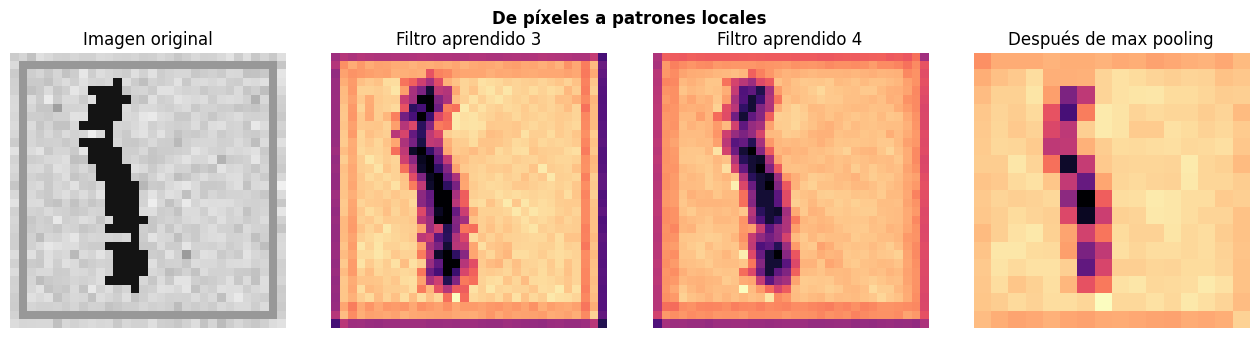

Tamaño antes de pooling: (32, 32) → después: (16, 16)


In [6]:
# Imagen de prueba independiente: una grieta vertical.
ejemplo = crear_baldosa(1, np.random.default_rng(2026))
entrada = torch.tensor(ejemplo[None, None, :, :])
cnn.eval()
with torch.no_grad():
    mapas = torch.relu(cnn[0](entrada))[0]          # 12 × 32 × 32
    agrupados = nn.functional.max_pool2d(mapas, 2) # 12 × 16 × 16

variaciones = mapas.flatten(1).std(dim=1)
seleccion = torch.topk(variaciones, 2).indices.tolist()

fig, ejes = plt.subplots(1, 4, figsize=(13, 3.4))
ejes[0].imshow(ejemplo, cmap="gray", vmin=0, vmax=1)
ejes[0].set_title("Imagen original")
ejes[1].imshow(mapas[seleccion[0]].numpy(), cmap="magma")
ejes[1].set_title(f"Filtro aprendido {seleccion[0]+1}")
ejes[2].imshow(mapas[seleccion[1]].numpy(), cmap="magma")
ejes[2].set_title(f"Filtro aprendido {seleccion[1]+1}")
ejes[3].imshow(agrupados[seleccion[0]].numpy(), cmap="magma")
ejes[3].set_title("Después de max pooling")
for eje in ejes:
    eje.axis("off")
plt.suptitle("De píxeles a patrones locales", fontweight="bold")
plt.tight_layout()
plt.show()
print("Tamaño antes de pooling:", tuple(mapas.shape[-2:]),
      "→ después:", tuple(agrupados.shape[-2:]))

### 7. 🕹️ Demo: inspeccionar una baldosa nueva

La siguiente función genera **una imagen nueva** y la pasa por el modelo entrenado. Muestra su **predicción** y las **probabilidades de las tres clases**.

**Para probar en clase:** cambia `tipo` entre `"sin grieta"`, `"vertical"` y `"horizontal"`; cambia `semilla` para generar otra baldosa del mismo tipo. Ejecuta nuevamente esta última celda y observa cómo responde la CNN.

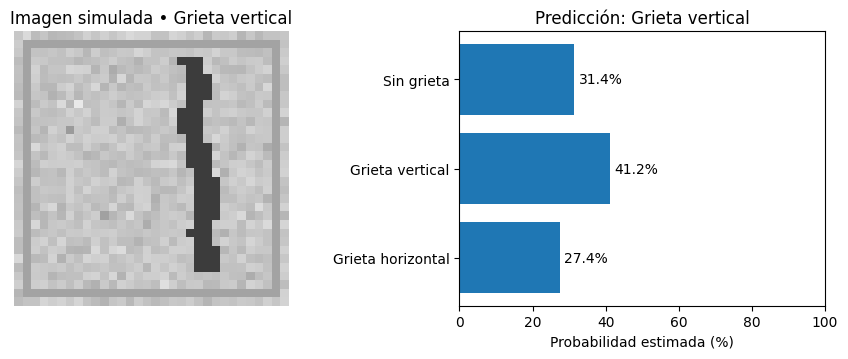

✅ ACIERTO | Real: Grieta vertical | Predicción: Grieta vertical


In [7]:
def inspeccionar(tipo="vertical", semilla=405):
    opciones = {"sin grieta": 0, "vertical": 1, "horizontal": 2}
    if tipo not in opciones:
        raise ValueError("Usa: 'sin grieta', 'vertical' u 'horizontal'.")

    clase_real = opciones[tipo]
    imagen = crear_baldosa(clase_real, np.random.default_rng(semilla))
    tensor = torch.tensor(imagen[None, None, :, :])
    cnn.eval()
    with torch.no_grad():
        probabilidades = torch.softmax(cnn(tensor), dim=1)[0].numpy()
    prediccion = int(np.argmax(probabilidades))

    fig, ejes = plt.subplots(1, 2, figsize=(9, 3.7))
    ejes[0].imshow(imagen, cmap="gray", vmin=0, vmax=1)
    ejes[0].axis("off")
    ejes[0].set_title(f"Imagen simulada • {NOMBRES[clase_real]}")
    ejes[1].barh(NOMBRES[::-1], probabilidades[::-1] * 100)
    ejes[1].set_xlim(0, 100)
    ejes[1].set_xlabel("Probabilidad estimada (%)")
    ejes[1].set_title(f"Predicción: {NOMBRES[prediccion]}")
    for i, p in enumerate(probabilidades[::-1]):
        ejes[1].text(min(p * 100 + 1.2, 95), i, f"{p:.1%}", va="center")
    plt.tight_layout()
    plt.show()

    estado = "✅ ACIERTO" if prediccion == clase_real else "❌ ERROR"
    print(f"{estado} | Real: {NOMBRES[clase_real]} | Predicción: {NOMBRES[prediccion]}")
    return probabilidades

# CAMBIA ESTOS DOS VALORES Y VUELVE A EJECUTAR:
tipo = "vertical"       # "sin grieta", "vertical", "horizontal"
semilla = 405            # por ejemplo: 405, 100, 2026, 89...
_ = inspeccionar(tipo, semilla)

---
### 8. Interpretación para tu exposición

**En 60–90 segundos puedes explicar:**

> “Para demostrar las redes neuronales convolucionales, creé *BaldosaScan*, un pequeño inspector de grietas. Primero genero tres clases de baldosas artificiales, con ligeras variaciones, y separo los datos en entrenamiento, validación y prueba. Después entreno una CNN que utiliza convoluciones para aprender patrones locales, max pooling para reducir el tamaño y una capa densa para clasificar. Comparo sus resultados con una red sin convoluciones y visualizo los mapas producidos por los filtros. Finalmente creo una baldosa nueva y el sistema predice si está intacta o si la grieta es vertical u horizontal. Esto ilustra cómo la CNN reutiliza detectores de patrones sin tener que programar manualmente cada tipo de grieta.”

**Lo que demuestra:** convolución, filtros aprendidos, ReLU, pooling, GAP, entrenamiento, clasificación y evaluación con datos no vistos.

**Lo que NO demuestra:** detección confiable de grietas en fotografías reales. Para eso harían falta imágenes reales etiquetadas, evaluación más rigurosa y pruebas en distintas superficies e iluminaciones.

**Cómo adaptar tu diapositiva 14:** usa el título **“BaldosaScan: CNN para inspección visual”**, coloca una imagen de la galería, la curva de precisión y una captura de la demo. Describe el dataset como **“simulado, creado en Python”** y evita presentarlo como un producto industrial validado.